# 2 · Planning for the average

Run AVR-04's GA at the design utilization, check that the FH clock reproduces AVR-04's evaluator, then judge the plan on futures it did not expect. See [Lesson 2](../docs/lessons/02-planning-for-the-average.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from fracsched.problem import small_problem
from fracsched.utilization_model import default_model

rng = np.random.default_rng(1)
problem = small_problem(0)  # AVR-04's small instance on the flight-hour clock
model = default_model()

In [2]:
from pmo.evaluate import evaluate as pmo_evaluate
from pmo.ga import GAConfig

from fracsched.deterministic_baseline import average_plan, constant_scenario
from fracsched.scenarios import evaluate, evaluate_in_chunks, segment_tables

plan = average_plan(problem, GAConfig(pop_size=40, generations=60, seed=0)).schedule
at_mean = evaluate(problem, segment_tables(problem, constant_scenario(problem)), plan)
print("this project at ū:", round(at_mean.total[0], 2))
print("AVR-04's evaluator:", round(pmo_evaluate(problem.at_mean(), plan).total_cost, 2))

u, _ = model.sample(rng, 1000, 3, 26)
(ev,) = evaluate_in_chunks(problem, u, [plan])
print(f"expected cost {ev.total.mean():,.0f} vs promised {at_mean.total[0]:,.0f}")
print("mean forced tasks:", ev.forced_tasks.mean())

this project at ū: 353766.75
AVR-04's evaluator: 353766.75


expected cost 417,886 vs promised 353,767
mean forced tasks: 1.008


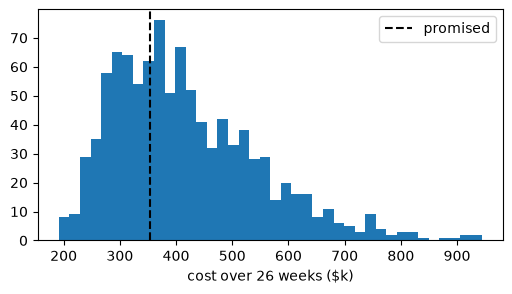

In [3]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(ev.total / 1e3, bins=40)
ax.axvline(at_mean.total[0] / 1e3, color="k", ls="--", label="promised")
ax.set_xlabel("cost over 26 weeks ($k)")
ax.legend();